In [1]:
from data_analysis_utils import *

# No TDD, no refinement
DEFAULT_PREFIX = "default"
DEFAULT_SUBFOLDERS = ["default_0_54", "default_55_109", "default_110_163"]

# No TDD, refinement
REF_PREFIX = ""
REF_SUBFOLDERS = []

# TDD, no refinement
TDD_PREFIX = ""
TDD_SUBFOLDERS = []

# TDD, refinement
TDD_REF_PREFIX = "tdd_refine"
TDD_REF_SUBFOLDERS = ["my_experiment"]

AGENT_SCENARIOS = {
    "default": (DEFAULT_PREFIX, DEFAULT_SUBFOLDERS),
    "tdd_refine": (TDD_REF_PREFIX, TDD_REF_SUBFOLDERS)
}

df_summaries = aggregate_json(agent_scenarios=AGENT_SCENARIOS)

#df_default = aggregate_csv(prefix=DEFAULT_PREFIX, subfolders=DEFAULT_SUBFOLDERS)
df_instances = aggregate_csv_scenarios(AGENT_SCENARIOS)
df_instances = add_unrolled_token_cost_column(df_instances)


In [2]:
df_summaries.head()

,total,passed,pass_rate,avg_iters,tokens_input,tokens_output,avg_line_coverage,avg_branch_coverage,avg_mutation_score,tokens_a11_input,tokens_a11_output,tokens_a12_input,tokens_a12_output,tokens_a2_input,tokens_a2_output,tokens_a3_input,tokens_a3_output,tokens_a4_input,tokens_a4_output
scenario,,,,,,,,,,,,,,,,,,,
default,164,133,0.810976,1.00000,3184384,1429468,0.000000,0.0,-1.0,0,0,0,0,2197312,1099977,987072,329491,0,0
tdd_refine,51,45,0.882353,1.54902,12781773,2008074,43.917647,0.0,-1.0,2080851,507654,3705813,893265,3568674,296922,83691,26265,3342744,283968


In [3]:
df_instances.head()

,scenario,batch,pipeline_tests_passed,pipeline_iterations,coverage_tests_run,coverage_tests_failed,coverage_tests_errors,coverage_tests_passed,coverage_test_file,coverage_patch_file,...,a12_output_tokens,a2_input_tokens,a2_output_tokens,a3_input_tokens,a3_output_tokens,a4_input_tokens,a4_output_tokens,instance_id,token_cost_cumulative,token_cost_unrolled
0,default,default_0_54,False,1,0,0,0,False,NaN,NaN,...,0,230,72,0,0,0,0,1,302,302.0
1,default,default_0_54,False,1,0,0,0,False,NaN,NaN,...,0,451,199,0,0,0,0,2,650,348.0
2,default,default_0_54,False,1,0,0,0,False,NaN,NaN,...,0,642,212,229,26,0,0,3,1109,459.0
3,default,default_0_54,False,1,0,0,0,False,NaN,NaN,...,0,867,266,229,26,0,0,4,1388,279.0
4,default,default_0_54,False,1,0,0,0,False,NaN,NaN,...,0,1090,335,229,26,0,0,5,1680,292.0


c:\Users\rapha\Desktop\MSc Computer Science\CS4570 Machine Learning for Software Engineering\tdlite\data_analysis\data_analysis_utils.py:477: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axis.legend()


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,default,tdd_refine,passed,0.810976,0.882353,164.0,51.0,133.0,45.0,0.29205,False


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,tdd_refine,token_cost_unrolled,513.969512,5686.215686,1.881929e-26,True


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,tdd_refine,pipeline_iterations,1.0,1.54902,2.966132e-11,True


Token cost summary:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,513.969512,323.0,1468.664547,187.0,18746.0
tdd_refine,51,5686.215686,3375.0,7440.474107,2288.0,50943.0


Iterations summary:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,1.00000,1.0,0.000000,1,1
tdd_refine,51,1.54902,1.0,1.361084,1,8


Test quality summary:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,0.000000,0.0,0.000000,0.0,0.0
tdd_refine,51,43.917647,50.0,29.286454,0.0,100.0


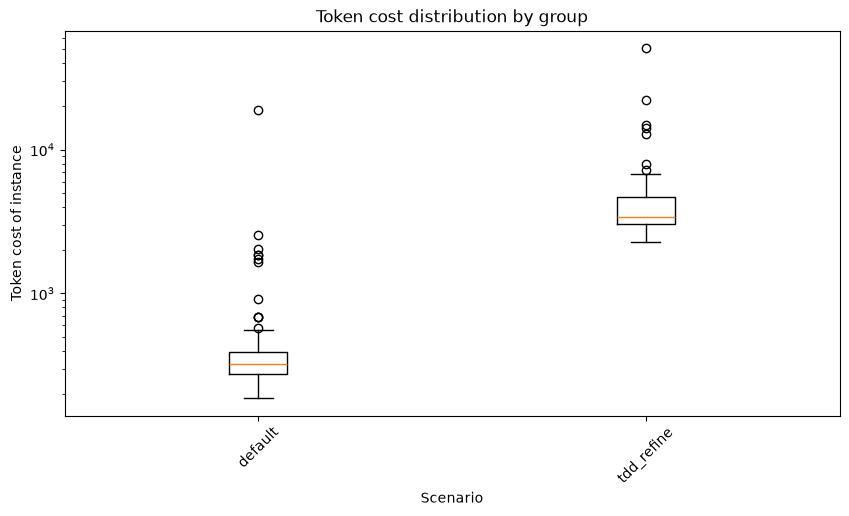

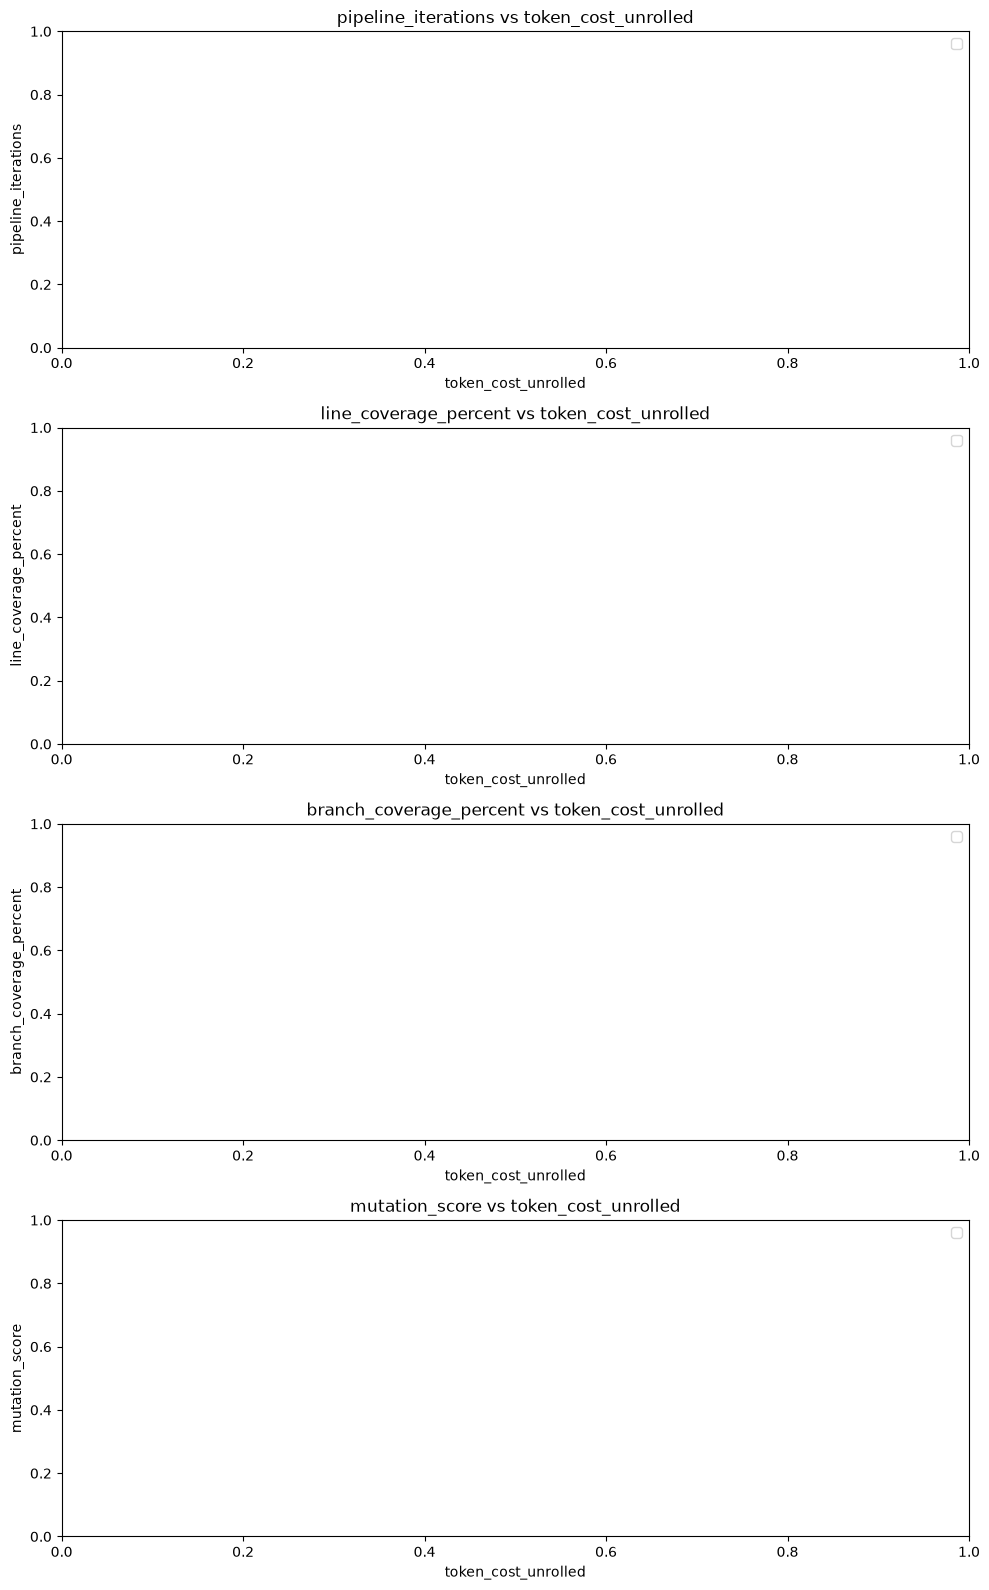

In [5]:
# Analyze and compare probability distributions of metrics in different scenarios

group_col = "scenario"
token_cost_summary = summarize_numeric_by_group(df_instances, group_col, "token_cost_unrolled")
iterations_summary = summarize_numeric_by_group(df_instances, group_col, "pipeline_iterations")
quality_summary = summarize_numeric_by_group(df_instances, group_col, "line_coverage_percent", drop_negative=True)

ax = plot_token_cost_distribution(df_instances, group_col=group_col)
axes = plot_metric_relationships(df_instances, group_col=group_col)

scenario_names = list(df_instances["scenario"].dropna().unique())
if len(scenario_names) >= 2:
    display(compare_pass_rates(df_summaries, scenario_names[0], scenario_names[1]))
    display(compare_token_costs(df_instances, scenario_names[0], scenario_names[1]))
    display(compare_quality_metric(df_instances, scenario_names[0], scenario_names[1], metric_col="pipeline_iterations"))
else:
    print("Only one scenario is present in AGENT_SCENARIOS. Add another scenario to run cross-scenario significance tests.")

print("Token cost summary:")
display(token_cost_summary)
print("Iterations summary:")
display(iterations_summary)
print("Test quality summary:")
display(quality_summary)
